## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00381ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.29s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.33s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_actatt 1.2 [c2df9d6b|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_vol_vol_actatt 1.2 [c2df9d6b|acaee5f1ce9f88de]'
00: ======================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_actatt ec62fa1b/last.pt'... done; this took 8.67ms.
01:   Model is ready. Current epoch to train is 1.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_actatt ec62fa1b/.
00: Launching 'AEC train_vol_vol_actatt 1.2 [c2df9d6b|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 256 for valuation.
01:   This model has 171745 parameters.
01:   Resuming from epoch 1.
00: Training epoch 2/1000 error avg trn 1042 [40s] learning rate 1.00e-03 grad norm 5.36

V0502 22:20:49.148000 28607 torch/_dynamo/guards.py:4760] [2/1] [__recompiles] Recompiling function valuation in /home/hans/python/quant_data/quantdata/dysanos/simple/trainer.py:310
V0502 22:20:49.148000 28607 torch/_dynamo/guards.py:4760] [2/1] [__recompiles]     triggered by the following guard failure(s):
V0502 22:20:49.148000 28607 torch/_dynamo/guards.py:4760] [2/1] [__recompiles]     - 2/0: tensor 'batch['ask_pure_price']' size mismatch at index 0. expected 256, actual 155
V0502 22:20:50.528000 28607 torch/_dynamo/guards.py:4760] [2/2] [__recompiles] Recompiling function valuation in /home/hans/python/quant_data/quantdata/dysanos/simple/trainer.py:310
V0502 22:20:50.528000 28607 torch/_dynamo/guards.py:4760] [2/2] [__recompiles]     triggered by the following guard failure(s):
V0502 22:20:50.528000 28607 torch/_dynamo/guards.py:4760] [2/2] [__recompiles]     - 2/1: tensor 'batch['ask_pure_price']' size mismatch at index 0. expected 155, actual 103
V0502 22:20:50.528000 28607 torc

00: Training 'train_vol_vol_actatt' epoch 2/1000 error avg trn 1042; val 50.25/67.38 [40s 2s 1.6s]. LR: 1.00e-03, GN 5.368, excess_weighted: 0.003421/0.003252, excess_weighted_avg: 0.00401/0.003386, excess_spread: 54.22/67.65, excess_spread_avg: 51.34/67.65, excess: 0.005497/0.003828, excess_avg: 0.005252/0.003828. ETA: 12:28:52.
01:   Epoch 2: Saving new best validation loss 67.38 vs. 2196 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_actatt ec62fa1b/best.pt'... done; this took 0.022s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_actatt ec62fa1b/last.pt... done; this took 8.45ms.


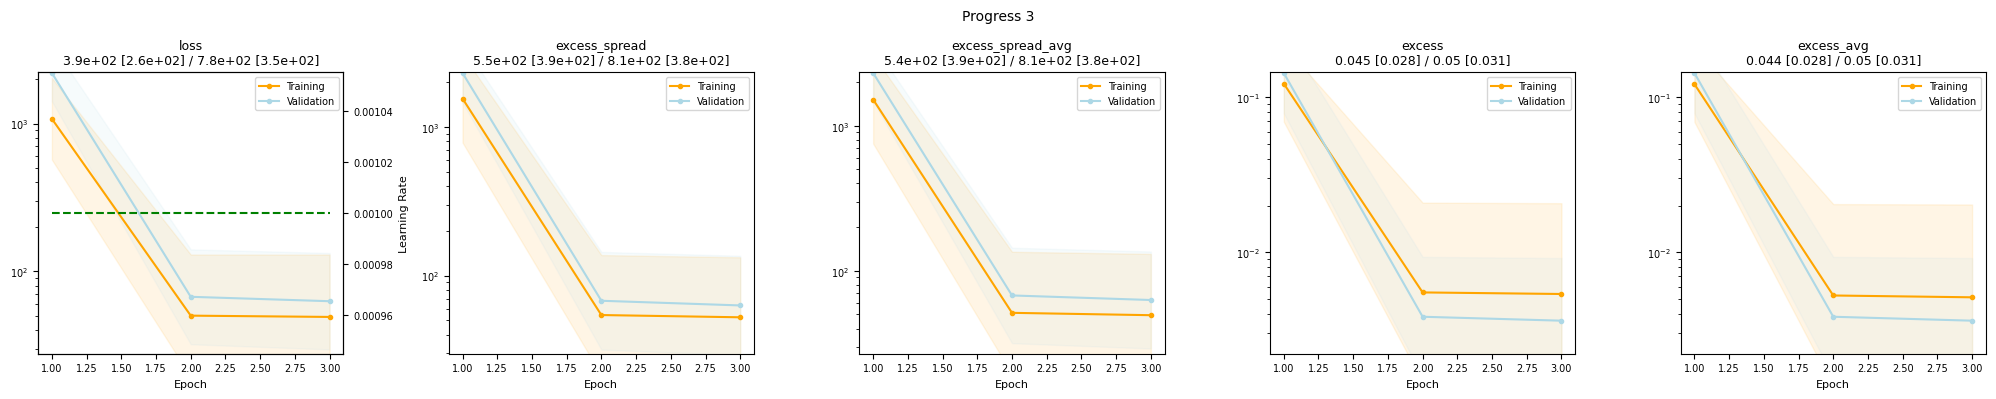

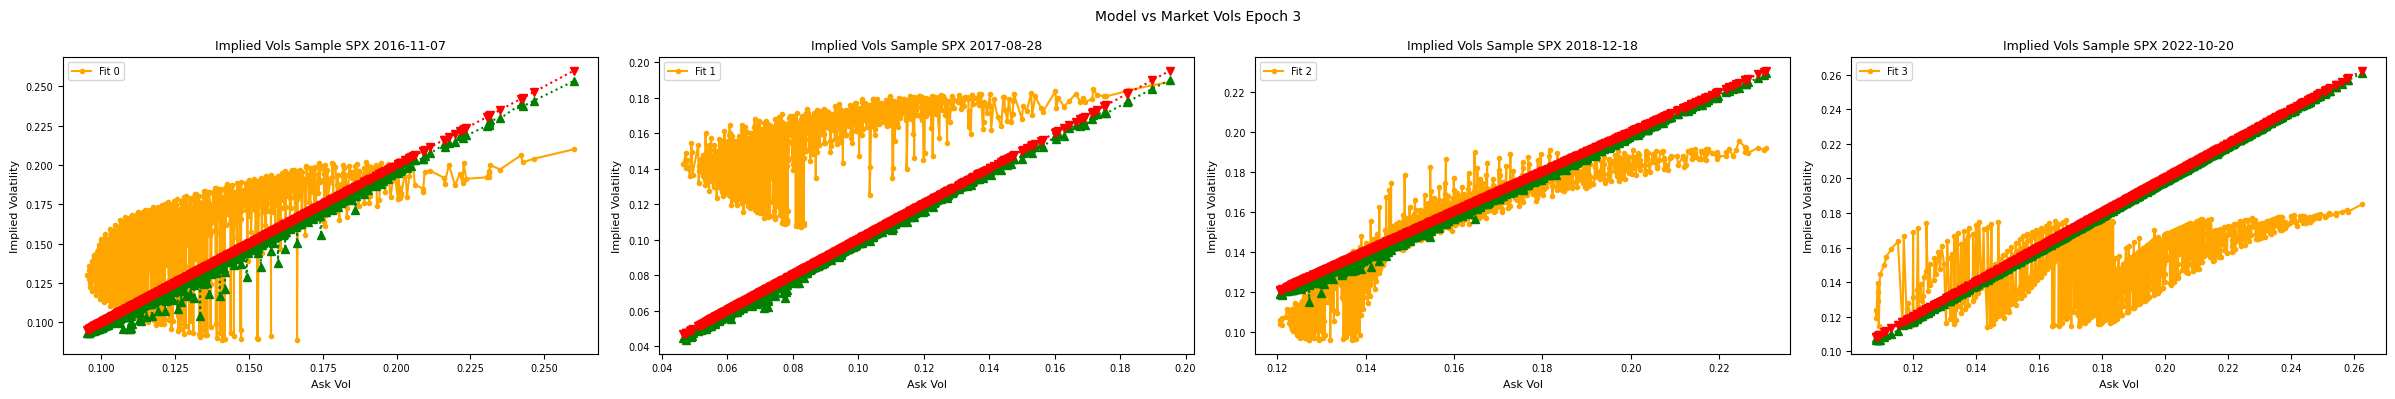

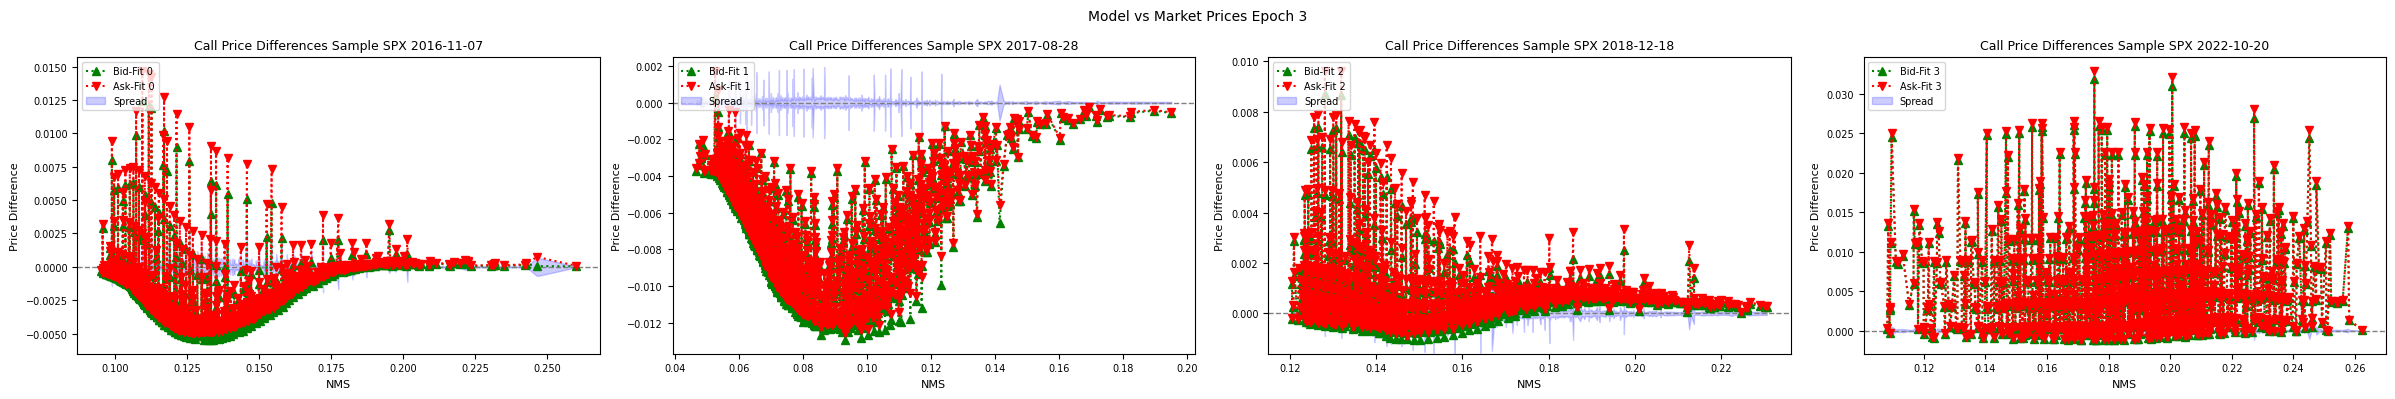

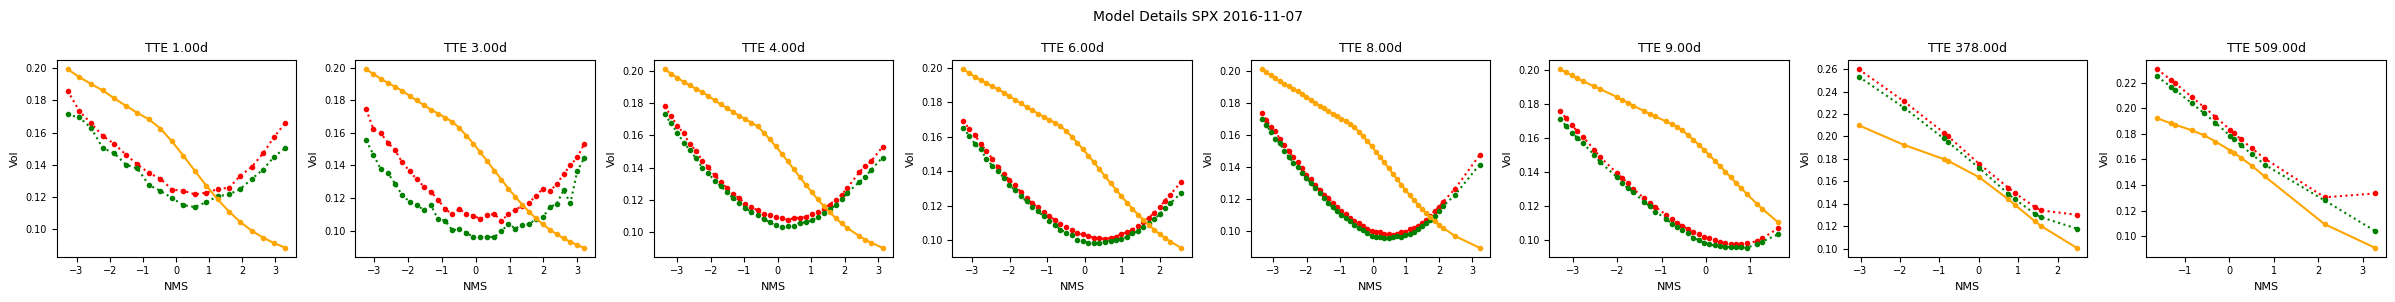

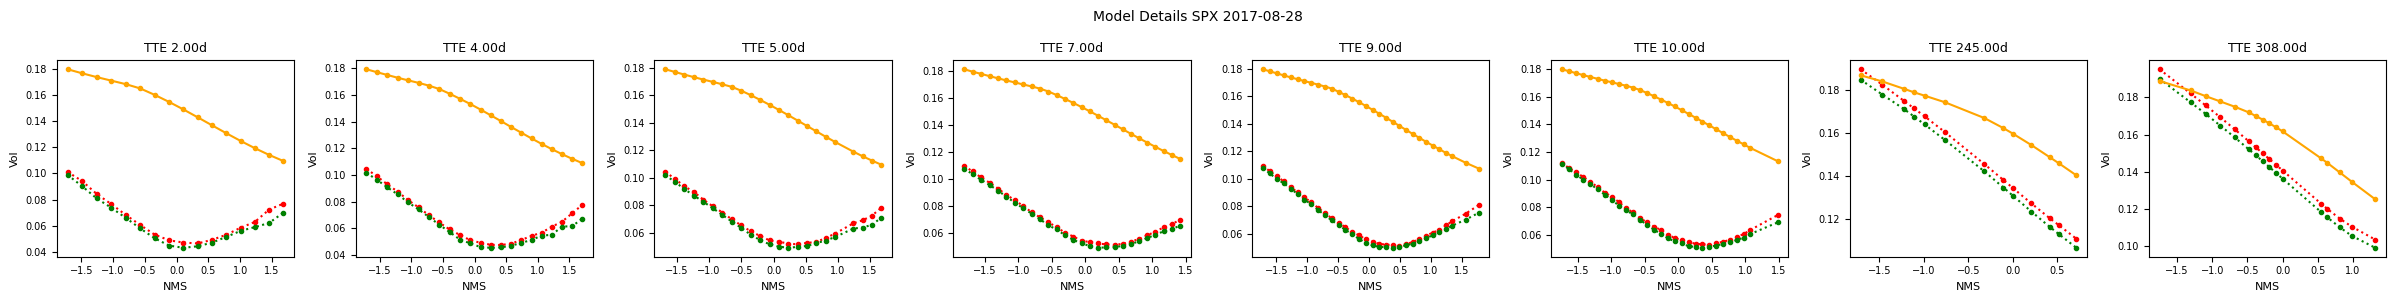

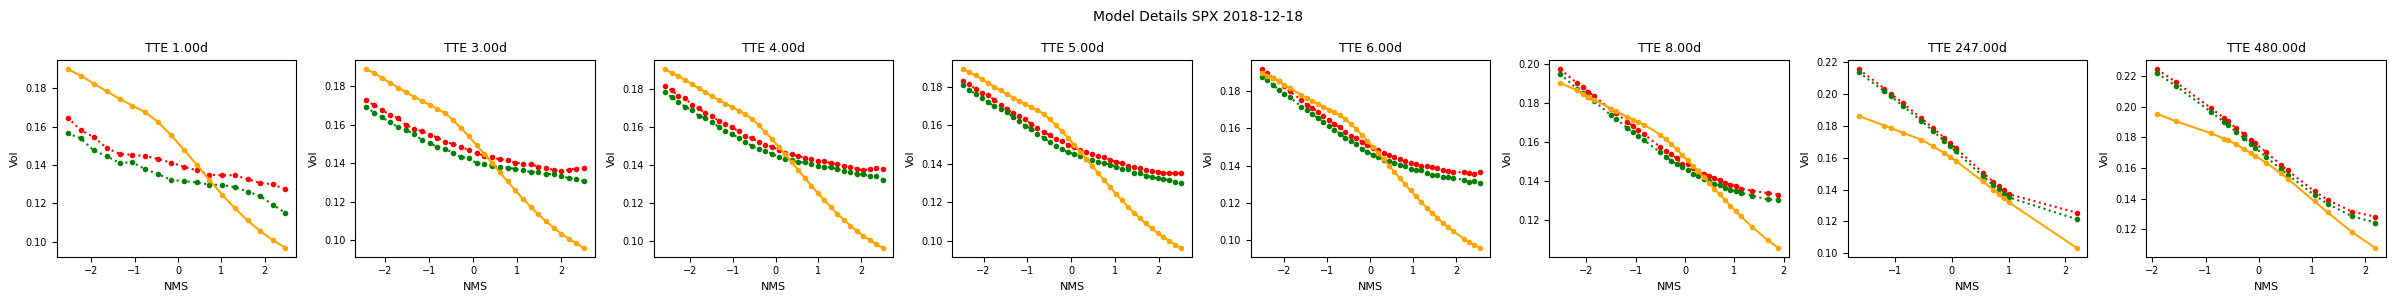

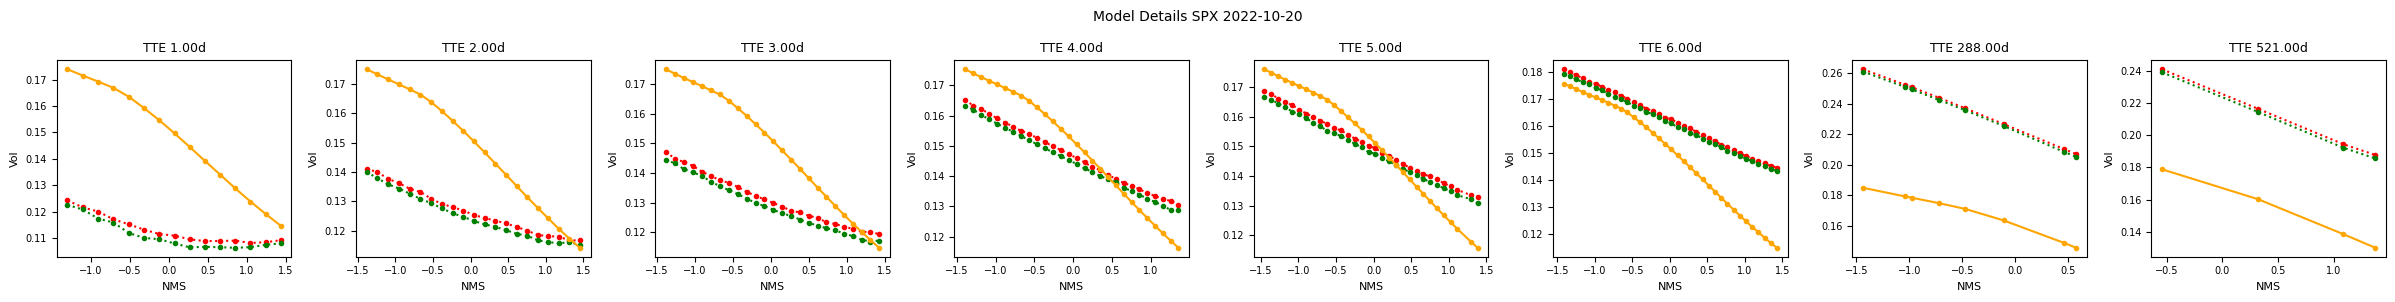

00: Training 'train_vol_vol_actatt' epoch 3/1000 error avg trn 51.88; val 49.25/62.9 [35s 1.6s 0.86s]. LR: 1.00e-03, GN 10.49, excess_weighted: 0.003304/0.003025, excess_weighted_avg: 0.003933/0.003196, excess_spread: 52.36/62.93, excess_spread_avg: 49.45/62.93, excess: 0.00537/0.00361, excess_avg: 0.005112/0.00361. ETA: 21:51:30.
00: Training epoch 4/1000 mini batch 89/100 with learning rate 1.00e-03: so far this took 26s...   

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = LatentAttentionEncoderFactory(
        num_head = 16,
        num_QK = 8,
        num_latent = 8,
        KV_config = FeedForward.Config(
            num_depth = 1,
            num_width = 32, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 128, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=256 )
